# Country Development Clustering

Cluster countries using eight World Bank indicators covering demography, health, education, technology, urbanization, and income. Values are the latest available for each indicator within 2010–2023; observation years can differ by indicator and country.


In [1]:
# Standard library imports
import json
import time
import urllib.request
import urllib.error
from functools import reduce
import warnings

# Data analysis imports
import numpy as np
import pandas as pd

# Visualization imports
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning imports
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Hierarchical clustering imports
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings("ignore")

# Professional plotting style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["legend.fontsize"] = 9
plt.rcParams["font.size"] = 10

RANDOM_STATE = 42

def plot_distributions(data, columns, plot_type, color, title_prefix, xlabel, ylabel):
    """Plots distributions (histograms or boxplots) for specified columns.

    Args:
        data (pd.DataFrame): The DataFrame containing the data.
        columns (list): List of column names to plot.
        plot_type (str): 'hist' for histogram, 'box' for boxplot.
        color (str): Color for the plots.
        title_prefix (str): Prefix for the plot titles.
        xlabel (str): Label for the x-axis (hist) or common label (box).
        ylabel (str): Label for the y-axis (hist) or common label (box).
    """
    fig, axes = plt.subplots(4, 2, figsize=(15, 16))
    axes = axes.flatten()

    for ax, column in zip(axes, columns):
        if plot_type == 'hist':
            sns.histplot(data[column], kde=True, color=color, edgecolor="white", ax=ax)
            ax.set_xlabel(xlabel)
            ax.set_ylabel(ylabel)
        elif plot_type == 'box':
            sns.boxplot(y=data[column], color=color, ax=ax)
            ax.set_ylabel(xlabel)
        ax.set_title(f"{title_prefix} {column}")

    plt.tight_layout()
    plt.show()


Matplotlib is building the font cache; this may take a moment.


## 1. Get the Data

We pull 8 key indicators (Wealth, Health, Education, and Tech) directly from the **World Bank API** for the years 2010–2023.

In [2]:
# Settings and indicator codes
INDICATORS = {
    "Birth Rate": "SP.DYN.CBRT.IN",
    "Fertility Rate": "SP.DYN.TFRT.IN",
    "Literacy Rate": "SE.ADT.LITR.ZS",
    "Female Secondary Enrollment": "SE.SEC.ENRR.FE",
    "GDP per Capita": "NY.GDP.PCAP.CD",
    "Life Expectancy": "SP.DYN.LE00.IN",
    "Internet Usage": "IT.NET.USER.ZS",
    "Urban Population": "SP.URB.TOTL.IN.ZS",
}

START_YEAR, END_YEAR = 2010, 2023
BASE_URL = "https://api.worldbank.org/v2"
feature_columns = list(INDICATORS.keys())
print(f"Setup complete for {len(feature_columns)} indicators.")

Setup complete for 8 indicators.


In [3]:
def get_json_from_url(url, retries=3, wait_seconds=2):
    """Download JSON data from a URL with a small retry loop."""
    for attempt in range(retries):
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(request, timeout=60) as response:
                return json.loads(response.read().decode("utf-8"))
        except (urllib.error.URLError, TimeoutError) as error:
            if attempt == retries - 1:
                raise error
            time.sleep(wait_seconds)


def fetch_countries():
    """Fetch country metadata and remove World Bank aggregate regions."""
    url = f"{BASE_URL}/country?format=json&per_page=400"
    payload = get_json_from_url(url)

    rows = []
    for item in payload[1]:
        rows.append(
            {
                "country_code": item["id"],
                "country": item["name"],
                "region": item["region"]["value"],
                "income_group": item["incomeLevel"]["value"],
            }
        )

    countries = pd.DataFrame(rows)
    countries = countries[countries["region"] != "Aggregates"].reset_index(drop=True)
    return countries


def fetch_indicator(indicator_code, indicator_name, start_year=START_YEAR, end_year=END_YEAR):
    """Fetch one indicator and keep the latest available value for each country."""
    url = (
        f"{BASE_URL}/country/all/indicator/{indicator_code}"
        f"?format=json&date={start_year}:{end_year}&per_page=20000"
    )
    payload = get_json_from_url(url)

    records = []
    for item in payload[1]:
        value = item.get("value")
        country_code = item.get("countryiso3code")

        if value is not None and country_code:
            records.append(
                {
                    "country_code": country_code,
                    f"{indicator_name} Year": int(item["date"]),
                    indicator_name: float(value),
                }
            )

    indicator_df = pd.DataFrame(records)

    # Keep the newest available observation for every country.
    indicator_df = (
        indicator_df.sort_values(["country_code", f"{indicator_name} Year"], ascending=[True, False])
        .drop_duplicates("country_code")
        .reset_index(drop=True)
    )

    return indicator_df


In [4]:
import pandas as pd
from functools import reduce

# Load country metadata
countries = fetch_countries()

# Load each indicator into a list of DataFrames
indicator_frames = []
for indicator_name, indicator_code in INDICATORS.items():
    print(f"Downloading {indicator_name}...")
    indicator_frames.append(fetch_indicator(indicator_code, indicator_name))

# Merge country metadata with all indicator tables using reduce
# This concisely applies pd.merge cumulatively to the list of indicator_frames
# starting with the 'countries' DataFrame.
data = reduce(lambda left, right: pd.merge(left, right, on='country_code', how='left'), indicator_frames, countries.copy())

print("Data loaded successfully.")

Data loaded successfully.


In [5]:
# Display the first rows of the dataset
data.head()


,country_code,country,region,income_group,Birth Rate Year,Birth Rate,Fertility Rate Year,Fertility Rate,Literacy Rate Year,Literacy Rate,Female Secondary Enrollment Year,Female Secondary Enrollment,GDP per Capita Year,GDP per Capita,Life Expectancy Year,Life Expectancy,Internet Usage Year,Internet Usage,Urban Population Year,Urban Population
0,ABW,Aruba,Latin America & Caribbean,High income,2023,7.973,2023,1.602,2010.0,96.82,2022.0,140.441833,2023.0,34897.618393,2023,76.353,2017.0,97.170000,2023,61.835149
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2023,35.437,2023,4.840,2021.0,37.27,2023.0,45.159691,2023.0,413.757895,2023,66.035,2023.0,15.928400,2023,25.473053
2,AGO,Angola,Sub-Saharan Africa,Lower middle income,2023,37.588,2023,5.124,2023.0,68.18,2023.0,48.117539,2023.0,2885.513491,2023,64.617,2023.0,37.885899,2023,69.851503
3,ALB,Albania,Europe & Central Asia,Upper middle income,2023,10.244,2023,1.348,2023.0,97.68,2023.0,92.668293,2023.0,9740.702341,2023,79.602,2023.0,83.135592,2023,58.210609
4,AND,Andorra,Europe & Central Asia,High income,2023,6.859,2023,1.082,NaN,NaN,2023.0,99.468742,2023.0,46812.448450,2023,84.041,2023.0,94.214996,2023,88.820161


### Data Summary
Here is a look at our dataset and where we might be missing some information.

In [6]:
# Show head and missing values summary
display(data.head())
missing = data[feature_columns].isna().mean().mul(100).round(2).to_frame("Missing %")
display(missing.sort_values("Missing %", ascending=False))
print(f"Total countries: {len(data)}")

,country_code,country,region,income_group,Birth Rate Year,Birth Rate,Fertility Rate Year,Fertility Rate,Literacy Rate Year,Literacy Rate,Female Secondary Enrollment Year,Female Secondary Enrollment,GDP per Capita Year,GDP per Capita,Life Expectancy Year,Life Expectancy,Internet Usage Year,Internet Usage,Urban Population Year,Urban Population
0,ABW,Aruba,Latin America & Caribbean,High income,2023,7.973,2023,1.602,2010.0,96.82,2022.0,140.441833,2023.0,34897.618393,2023,76.353,2017.0,97.170000,2023,61.835149
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2023,35.437,2023,4.840,2021.0,37.27,2023.0,45.159691,2023.0,413.757895,2023,66.035,2023.0,15.928400,2023,25.473053
2,AGO,Angola,Sub-Saharan Africa,Lower middle income,2023,37.588,2023,5.124,2023.0,68.18,2023.0,48.117539,2023.0,2885.513491,2023,64.617,2023.0,37.885899,2023,69.851503
3,ALB,Albania,Europe & Central Asia,Upper middle income,2023,10.244,2023,1.348,2023.0,97.68,2023.0,92.668293,2023.0,9740.702341,2023,79.602,2023.0,83.135592,2023,58.210609
4,AND,Andorra,Europe & Central Asia,High income,2023,6.859,2023,1.082,NaN,NaN,2023.0,99.468742,2023.0,46812.448450,2023,84.041,2023.0,94.214996,2023,88.820161


,Missing %
Literacy Rate,36.87
Female Secondary Enrollment,9.68
Internet Usage,3.69
GDP per Capita,1.38
Birth Rate,0.00
Fertility Rate,0.00
Life Expectancy,0.00
Urban Population,0.00


Total countries: 217


The dataset contains countries, metadata, indicator values, and source-year columns.

In [7]:
# Data types for each column
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_code                      217 non-null    str    
 1   country                           217 non-null    str    
 2   region                            217 non-null    str    
 3   income_group                      217 non-null    str    
 4   Birth Rate Year                   217 non-null    int64  
 5   Birth Rate                        217 non-null    float64
 6   Fertility Rate Year               217 non-null    int64  
 7   Fertility Rate                    217 non-null    float64
 8   Literacy Rate Year                137 non-null    float64
 9   Literacy Rate                     137 non-null    float64
 10  Female Secondary Enrollment Year  196 non-null    float64
 11  Female Secondary Enrollment       196 non-null    float64
 12  GDP per Capita Year

Data types confirm numerical and categorical columns for clustering.

In [8]:
# Missing value analysis for the main indicators
missing_values = (
    data[feature_columns]
    .isna()
    .sum()
    .to_frame("missing_count")
)
missing_values["missing_percent"] = (missing_values["missing_count"] / len(data) * 100).round(2)
missing_values.sort_values("missing_percent", ascending=False)


,missing_count,missing_percent
Literacy Rate,80,36.87
Female Secondary Enrollment,21,9.68
Internet Usage,8,3.69
GDP per Capita,3,1.38
Birth Rate,0,0.00
Fertility Rate,0,0.00
Life Expectancy,0,0.00
Urban Population,0,0.00


Missing values exist for some indicators; these will be handled later.

In [9]:
# Descriptive statistics for the main numerical indicators
data[feature_columns].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Birth Rate,217.0,17.49,9.61,4.40,9.77,13.75,24.58,46.36
Fertility Rate,217.0,2.38,1.20,0.59,1.49,1.92,3.10,6.13
Literacy Rate,137.0,84.94,17.70,30.63,75.64,93.53,97.68,100.00
Female Secondary Enrollment,196.0,87.18,28.79,2.76,74.82,93.39,103.65,152.58
GDP per Capita,214.0,22013.93,32967.03,249.80,2678.46,7907.90,30020.54,256799.91
Life Expectancy,217.0,73.79,7.12,54.46,68.48,74.55,79.59,86.37
Internet Usage,209.0,69.62,26.59,6.67,51.20,80.00,90.38,100.00
Urban Population,217.0,62.61,23.24,14.68,43.25,63.66,81.16,100.00


### Stats & Recency
Checking the range of our numbers and ensuring we have up-to-date info for each country.

In [10]:
# Stats and latest years available
display(data[feature_columns].describe().T.round(2))
years = data[[col for col in data.columns if col.endswith(" Year")]].agg(["min", "max"]).T
years.columns = ["Oldest", "Newest"]
display(years)

,count,mean,std,min,25%,50%,75%,max
Birth Rate,217.0,17.49,9.61,4.40,9.77,13.75,24.58,46.36
Fertility Rate,217.0,2.38,1.20,0.59,1.49,1.92,3.10,6.13
Literacy Rate,137.0,84.94,17.70,30.63,75.64,93.53,97.68,100.00
Female Secondary Enrollment,196.0,87.18,28.79,2.76,74.82,93.39,103.65,152.58
GDP per Capita,214.0,22013.93,32967.03,249.80,2678.46,7907.90,30020.54,256799.91
Life Expectancy,217.0,73.79,7.12,54.46,68.48,74.55,79.59,86.37
Internet Usage,209.0,69.62,26.59,6.67,51.20,80.00,90.38,100.00
Urban Population,217.0,62.61,23.24,14.68,43.25,63.66,81.16,100.00


,Oldest,Newest
Birth Rate Year,2023.0,2023.0
Fertility Rate Year,2023.0,2023.0
Literacy Rate Year,2010.0,2023.0
Female Secondary Enrollment Year,2012.0,2023.0
GDP per Capita Year,2011.0,2023.0
Life Expectancy Year,2023.0,2023.0
Internet Usage Year,2014.0,2023.0
Urban Population Year,2023.0,2023.0


This table shows the range of observation years used for each variable within the 2010–2023 window.

### Exploring the Trends
Let's visualize how wealth (GDP) connects to health and how birth rates relate to fertility.

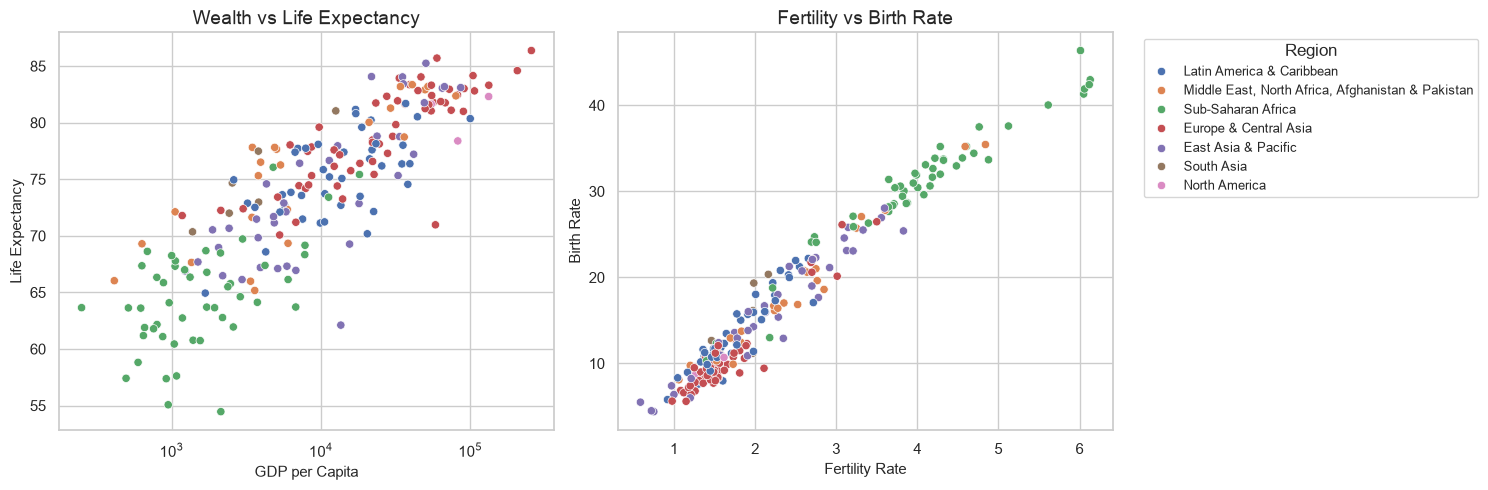

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=data, x="GDP per Capita", y="Life Expectancy", hue="region", ax=axes[0]).set(xscale="log", title="Wealth vs Life Expectancy")
sns.scatterplot(data=data, x="Fertility Rate", y="Birth Rate", hue="region", ax=axes[1]).set(title="Fertility vs Birth Rate")
axes[0].get_legend().remove(); axes[1].legend(title="Region", bbox_to_anchor=(1.05, 1))
plt.tight_layout(); plt.show()

## 2. Prepare for Modeling

We clean the data by keeping countries with enough info, filling in blanks with the median, and 'scaling' the values so no single indicator (like high GDP) dominates the math.

In [12]:
# Keep countries with at least 6 of the 8 indicators available.
# This removes countries with very limited data while keeping the dataset broad.
minimum_available_indicators = 6
available_indicator_count = data[feature_columns].notna().sum(axis=1)

model_data = data[available_indicator_count >= minimum_available_indicators].copy().reset_index(drop=True)

print(f"Countries before filtering: {len(data)}")
print(f"Countries after filtering:  {len(model_data)}")


Countries before filtering: 217
Countries after filtering:  211


In [13]:
# Fill missing indicators with medians, then standardize for clustering.
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_filled = imputer.fit_transform(model_data[feature_columns])
X_scaled = scaler.fit_transform(X_filled)

model_ready = model_data[["country_code", "country", "region", "income_group"]].copy()
model_ready[feature_columns] = X_filled
print(f"Ready: {len(model_ready)} countries.")


Ready: 211 countries.


### Cleaning & Scaling
We'll keep countries with enough data, fill blanks with the median, and scale everything so wealth doesn't overpower other factors.

## 3. K-means clustering

Compare values of k from 2 to 8. Four clusters are used for a more detailed descriptive view; the silhouette score favors two clusters, so the four-group solution should be treated as exploratory.


In [14]:
# Test several possible values of k
k_values = range(2, 9)
kmeans_results = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = kmeans.fit_predict(X_scaled)

    kmeans_results.append(
        {
            "k": k,
            "inertia": kmeans.inertia_,
            "silhouette": silhouette_score(X_scaled, labels),
        }
    )

kmeans_results = pd.DataFrame(kmeans_results)
kmeans_results


,k,inertia,silhouette
0,2,843.202031,0.455099
1,3,640.836217,0.300698
2,4,532.783706,0.271611
3,5,471.306629,0.257309
4,6,419.214233,0.241052
5,7,384.467812,0.240608
6,8,357.079892,0.217153


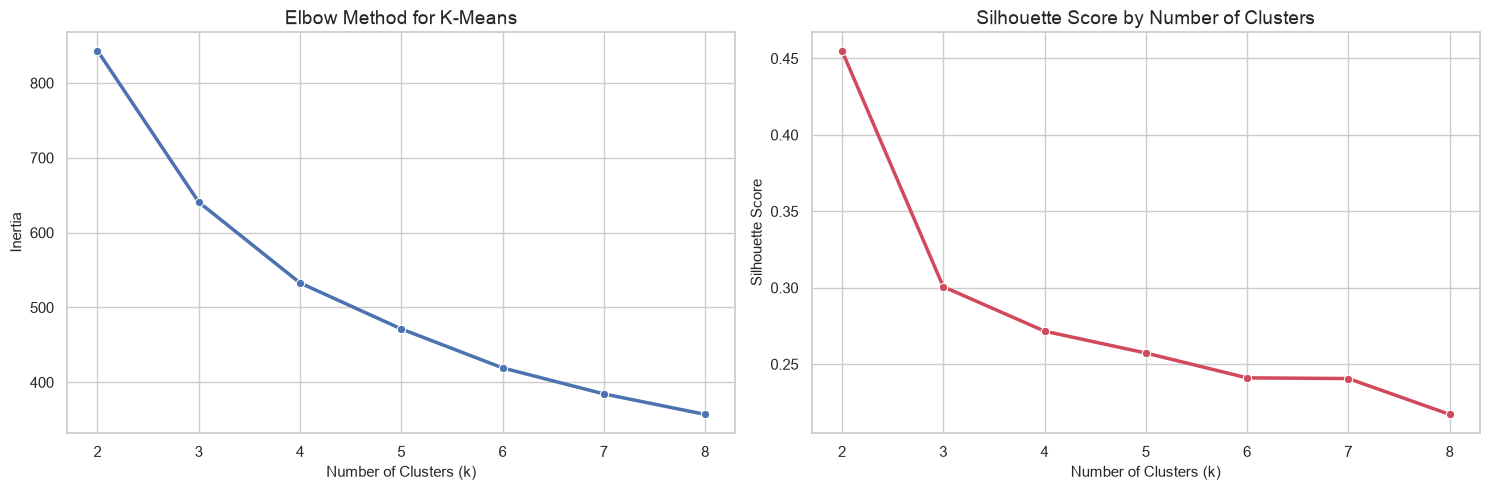

In [15]:
# Elbow Method and Silhouette Score plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(data=kmeans_results, x="k", y="inertia", marker="o", linewidth=2.5, ax=axes[0])
axes[0].set_title("Elbow Method for K-Means")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

sns.lineplot(data=kmeans_results, x="k", y="silhouette", marker="o", linewidth=2.5, color="#D1495B", ax=axes[1])
axes[1].set_title("Silhouette Score by Number of Clusters")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()


### Selected cluster count

The four-cluster solution gives more detailed profiles. It is an interpretability choice, not the best silhouette score.


In [16]:
# Fit the selected four-cluster model.
KMEANS_K = 4
kmeans_final = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_STATE, n_init=20)
model_ready["KMeans Cluster"] = kmeans_final.fit_predict(X_scaled)
kmeans_silhouette = silhouette_score(X_scaled, model_ready["KMeans Cluster"])
print(f"K-means silhouette score: {kmeans_silhouette:.3f}")


K-means silhouette score: 0.272


In [17]:
# Cluster sizes
kmeans_cluster_sizes = model_ready["KMeans Cluster"].value_counts().sort_index().to_frame("Number of Countries")
kmeans_cluster_sizes


,Number of Countries
KMeans Cluster,
0,49
1,44
2,34
3,84


### Cluster Profiles
Let's see what each group represents by looking at their average values.

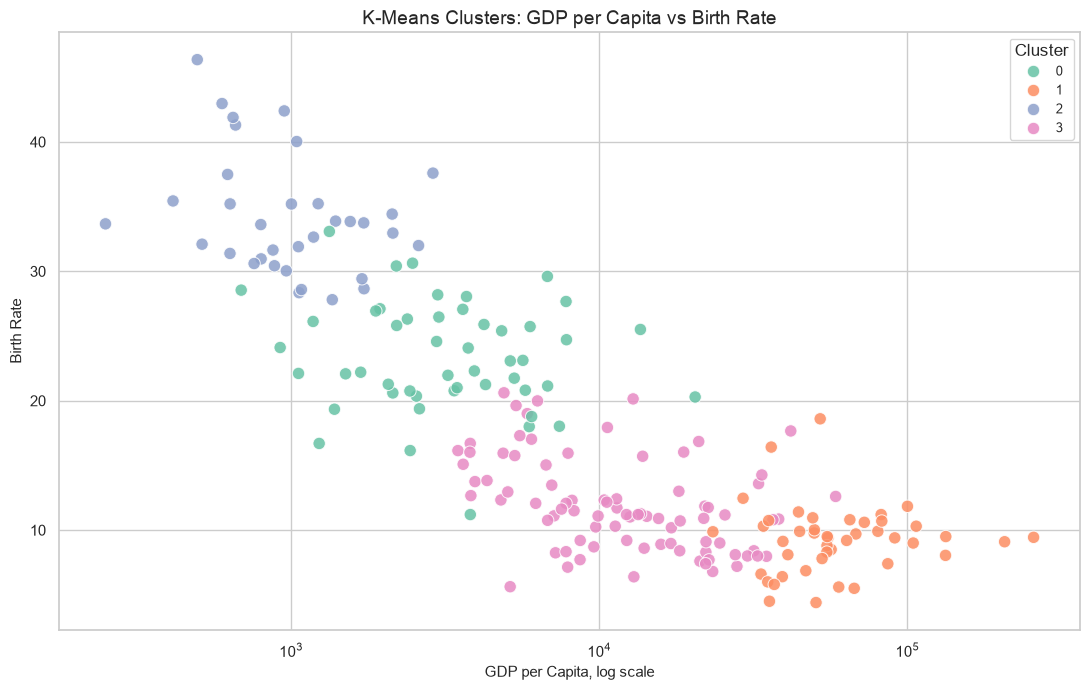

In [18]:
# Scatterplot of K-Means clusters
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=model_ready,
    x="GDP per Capita",
    y="Birth Rate",
    hue="KMeans Cluster",
    palette="Set2",
    s=80,
    alpha=0.85,
)
plt.xscale("log")
plt.title("K-Means Clusters: GDP per Capita vs Birth Rate")
plt.xlabel("GDP per Capita, log scale")
plt.ylabel("Birth Rate")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


This scatterplot visualizes K-Means clusters based on GDP per Capita and Birth Rate.

In [19]:
# Centroid visualization in the original units
centroids_original = pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=feature_columns,
)
centroids_original.index.name = "KMeans Cluster"
centroids_original.round(2)


,Birth Rate,Fertility Rate,Literacy Rate,Female Secondary Enrollment,GDP per Capita,Life Expectancy,Internet Usage,Urban Population
KMeans Cluster,,,,,,,,
0,23.39,2.92,89.02,81.58,4080.88,68.75,55.38,49.10
1,9.27,1.43,94.77,109.44,68088.31,82.29,93.35,86.37
2,34.23,4.54,61.25,44.64,1127.59,63.48,26.61,39.94
3,11.93,1.70,94.57,97.08,15051.51,76.16,83.15,66.67


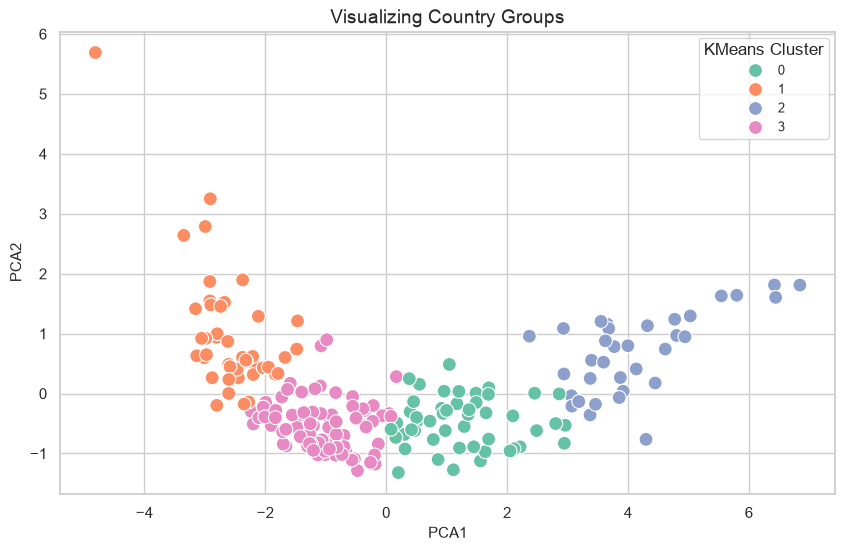

In [20]:
pca_coords = PCA(n_components=2).fit_transform(X_scaled)
model_ready["PCA1"], model_ready["PCA2"] = pca_coords[:, 0], pca_coords[:, 1]
plt.figure(figsize=(10, 6))
sns.scatterplot(data=model_ready, x="PCA1", y="PCA2", hue="KMeans Cluster", palette="Set2", s=100)
plt.title("Visualizing Country Groups"); plt.show()

### 2D View
Using PCA to flatten our 8 indicators into 2 dimensions so we can visualize the clusters.

In [21]:
# Describe clusters from standardized indicator means.
cluster_profile_scaled = pd.DataFrame(X_scaled, columns=feature_columns).assign(
    cluster=model_ready["KMeans Cluster"].to_numpy()
).groupby("cluster")[feature_columns].mean()

cluster_interpretation_rows = []
for cluster in sorted(model_ready["KMeans Cluster"].unique()):
    z_values = cluster_profile_scaled.loc[cluster].sort_values(ascending=False)
    example_countries = model_ready.loc[
        model_ready["KMeans Cluster"] == cluster, "country"
    ].head(8).tolist()
    cluster_interpretation_rows.append({
        "Cluster": cluster,
        "Highest relative indicators": ", ".join(z_values.head(3).index),
        "Lowest relative indicators": ", ".join(z_values.tail(3).index),
        "Example countries": ", ".join(example_countries),
    })

kmeans_interpretation = pd.DataFrame(cluster_interpretation_rows)
kmeans_interpretation


,Cluster,Highest relative indicators,Lowest relative indicators,Example countries
0,0,"Birth Rate, Fertility Rate, Literacy Rate","Internet Usage, Urban Population, Life Expectancy","Bangladesh, Belize, Bolivia, Botswana, Congo, ..."
1,1,"GDP per Capita, Life Expectancy, Urban Population","Literacy Rate, Fertility Rate, Birth Rate","Andorra, United Arab Emirates, Australia, Aust..."
2,2,"Fertility Rate, Birth Rate, GDP per Capita","Female Secondary Enrollment, Internet Usage, L...","Afghanistan, Angola, Burundi, Benin, Burkina F..."
3,3,"Internet Usage, Literacy Rate, Life Expectancy","GDP per Capita, Fertility Rate, Birth Rate","Aruba, Albania, Argentina, Armenia, Antigua an..."


### Cluster profiles

The table reports each cluster’s strongest and weakest indicators relative to the countries in this dataset. Cluster numbers are arbitrary identifiers, and these groups are descriptive rather than development rankings.


## 4. Hierarchical Clustering

Hierarchical clustering builds a tree-like structure (a dendrogram) showing how countries are related based on their similarities. Countries that connect lower down the tree are more alike.

We use **Ward linkage** because it's good for grouping numbers and tries to make compact, tight groups.

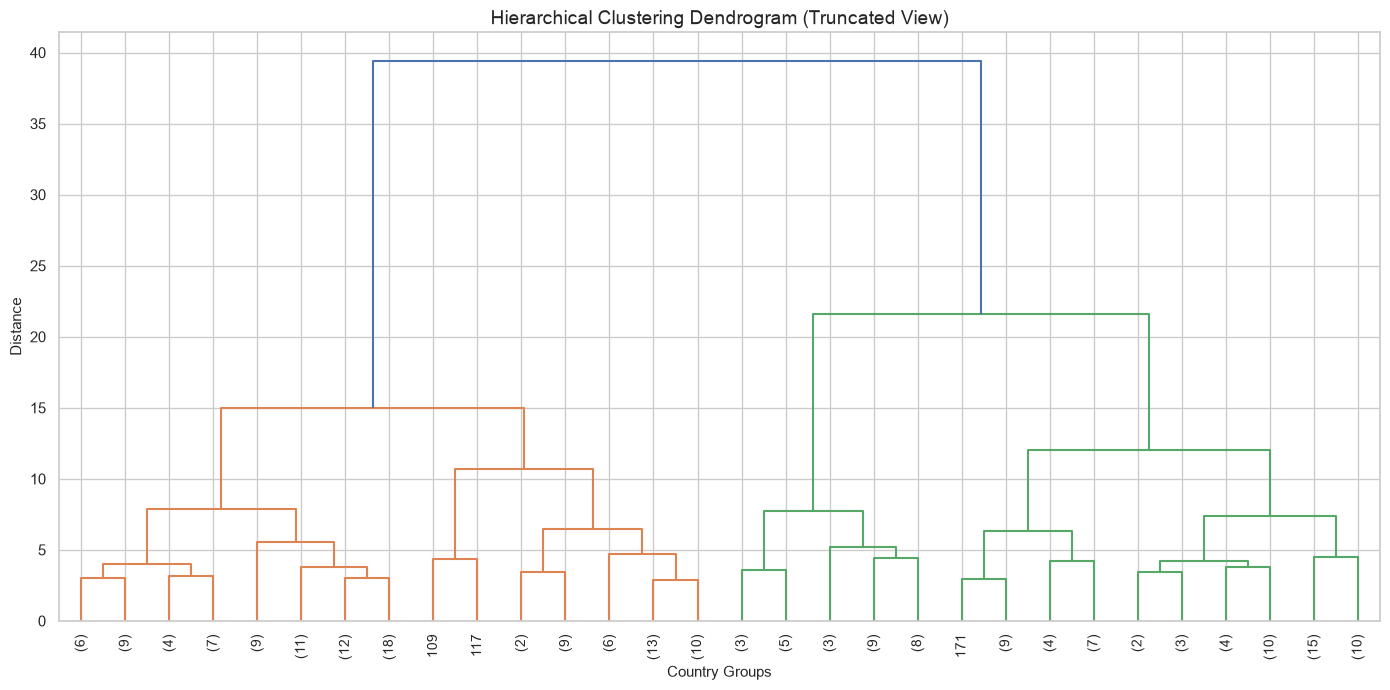

In [22]:
# Create linkage matrix for dendrogram
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 7))
dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    color_threshold=None,
)
plt.title("Hierarchical Clustering Dendrogram (Truncated View)")
plt.xlabel("Country Groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()


The dendrogram shows how countries merge into groups. 4 clusters will be used for hierarchical clustering for comparison with K-Means.

In [23]:
# Silhouette scores for hierarchical clustering with different numbers of clusters
hierarchical_results = []

for k in k_values:
    hierarchical_model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = hierarchical_model.fit_predict(X_scaled)

    hierarchical_results.append(
        {
            "k": k,
            "silhouette": silhouette_score(X_scaled, labels),
        }
    )

hierarchical_results = pd.DataFrame(hierarchical_results)
hierarchical_results


,k,silhouette
0,2,0.387207
1,3,0.333757
2,4,0.240061
3,5,0.229667
4,6,0.233001
5,7,0.203673
6,8,0.193701


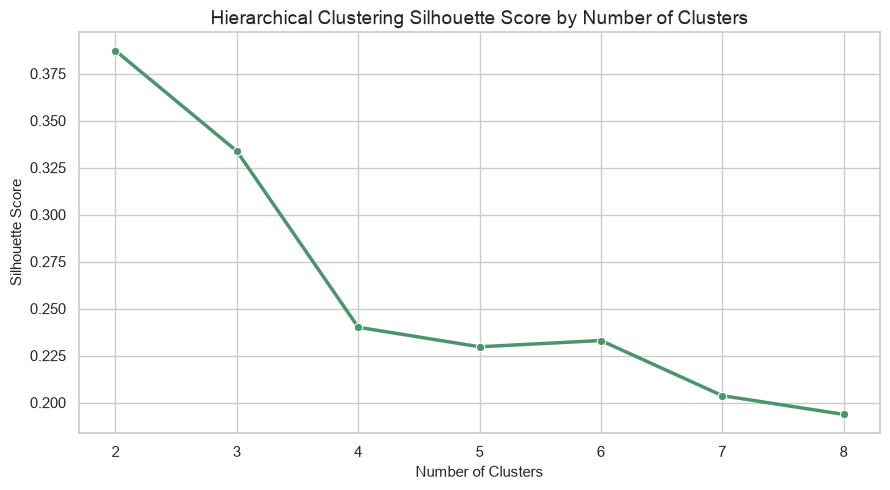

In [24]:
# Plot hierarchical silhouette scores
plt.figure(figsize=(9, 5))
sns.lineplot(data=hierarchical_results, x="k", y="silhouette", marker="o", linewidth=2.5, color="#4C956C")
plt.title("Hierarchical Clustering Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


In [25]:
# Final hierarchical clustering model
HIERARCHICAL_K = 4

hierarchical_final = AgglomerativeClustering(n_clusters=HIERARCHICAL_K, linkage="ward")
model_ready["Hierarchical Cluster"] = hierarchical_final.fit_predict(X_scaled)

hierarchical_silhouette = silhouette_score(X_scaled, model_ready["Hierarchical Cluster"])
print(f"Final Hierarchical Clustering silhouette score: {hierarchical_silhouette:.3f}")


Final Hierarchical Clustering silhouette score: 0.240


In [26]:
# Hierarchical cluster sizes
hierarchical_cluster_sizes = model_ready["Hierarchical Cluster"].value_counts().sort_index().to_frame("Number of Countries")
hierarchical_cluster_sizes


,Number of Countries
Hierarchical Cluster,
0,65
1,42
2,28
3,76


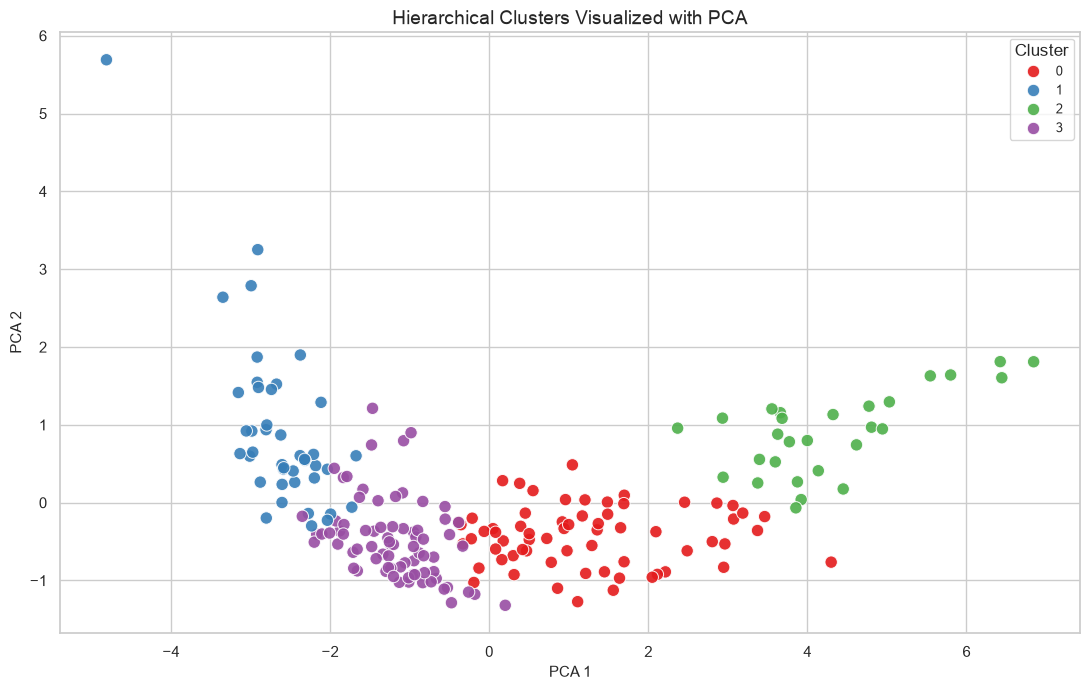

In [27]:
# Visualize hierarchical clusters using PCA coordinates
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=model_ready,
    x="PCA1",
    y="PCA2",
    hue="Hierarchical Cluster",
    palette="Set1",
    s=80,
    alpha=0.9,
)
plt.title("Hierarchical Clusters Visualized with PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


The PCA visualization shows hierarchical clusters in two dimensions for comparison with K-Means.

In [28]:
# Mean indicator values for each hierarchical cluster
hierarchical_profile = model_ready.groupby("Hierarchical Cluster")[feature_columns].mean().round(2)
hierarchical_profile


,Birth Rate,Fertility Rate,Literacy Rate,Female Secondary Enrollment,GDP per Capita,Life Expectancy,Internet Usage,Urban Population
Hierarchical Cluster,,,,,,,,
0,23.32,2.94,88.70,79.56,4163.63,69.12,56.47,50.42
1,8.73,1.35,94.80,109.05,68423.61,82.62,94.33,84.45
2,34.79,4.63,55.96,43.91,1144.27,62.94,28.28,41.89
3,11.37,1.66,95.31,98.74,17395.36,76.58,82.72,67.99


The hierarchical cluster profile table describes each group's characteristics, similar to K-Means.

## 5. Compare the models

Since there's no single 'right' answer in clustering, we use the **Silhouette Score** to judge how good our clusters are.

### What the silhouette score tells us

- A score close to **1** means countries fit nicely into their assigned clusters.
- Around **0** means clusters might be overlapping.
- Negative scores suggest some countries might be in the wrong cluster.

Generally, a higher score means our clusters are better separated.

In [29]:
# Compare final model performance
model_comparison = pd.DataFrame(
    {
        "Model": ["K-Means", "Hierarchical Clustering"],
        "Number of Clusters": [KMEANS_K, HIERARCHICAL_K],
        "Silhouette Score": [kmeans_silhouette, hierarchical_silhouette],
    }
)

model_comparison["Silhouette Score"] = model_comparison["Silhouette Score"].round(3)
model_comparison


,Model,Number of Clusters,Silhouette Score
0,K-Means,4,0.272
1,Hierarchical Clustering,4,0.240


### Interpretation

K-means and Ward hierarchical clustering give alternative partitions of the same standardized indicators. Silhouette scores provide a useful comparison, but do not establish that any cluster is a definitive country type.


In [30]:
# Optional: save final table for use in reports or presentations
final_country_clusters = model_ready[
    [
        "country_code",
        "country",
        "region",
        "income_group",
        "KMeans Cluster",
        "Hierarchical Cluster",
    ]
    + feature_columns
].copy()

final_country_clusters.head(10)


,country_code,country,region,income_group,KMeans Cluster,Hierarchical Cluster,Birth Rate,Fertility Rate,Literacy Rate,Female Secondary Enrollment,GDP per Capita,Life Expectancy,Internet Usage,Urban Population
0,ABW,Aruba,Latin America & Caribbean,High income,3,3,7.973,1.602,96.820000,140.441833,34897.618393,76.353000,97.170000,61.835149
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2,2,35.437,4.840,37.270000,45.159691,413.757895,66.035000,15.928400,25.473053
2,AGO,Angola,Sub-Saharan Africa,Lower middle income,2,2,37.588,5.124,68.180000,48.117539,2885.513491,64.617000,37.885899,69.851503
3,ALB,Albania,Europe & Central Asia,Upper middle income,3,3,10.244,1.348,97.680000,92.668293,9740.702341,79.602000,83.135592,58.210609
4,AND,Andorra,Europe & Central Asia,High income,1,1,6.859,1.082,93.527396,99.468742,46812.448450,84.041000,94.214996,88.820161
5,ARE,United Arab Emirates,"Middle East, North Africa, Afghanistan & Pakistan",High income,1,1,9.774,1.200,98.059998,102.195121,49850.694508,82.909000,100.000000,85.668070
6,ARG,Argentina,Latin America & Caribbean,Upper middle income,3,3,11.064,1.500,99.139999,107.980731,14261.846567,77.395000,89.228972,92.194513
7,ARM,Armenia,Europe & Central Asia,Upper middle income,3,3,12.300,1.900,99.839996,88.223202,8159.087210,77.465854,79.996630,65.695688
8,ATG,Antigua and Barbuda,Latin America & Caribbean,High income,3,3,11.848,1.578,93.527396,109.004009,22012.262595,77.598000,72.124100,24.450016
9,AUS,Australia,East Asia & Pacific,High income,1,1,10.800,1.499,93.527396,131.097336,65058.377315,83.051220,96.116096,87.486696


### Conclusion

The notebook collects World Bank indicators, handles missing values, scales the data, and compares two clustering methods. The four-cluster view is exploratory. Data availability varies by country and indicator, and mixing the latest available observations within 2010–2023 limits comparisons at a single point in time.
